# Notebook to extend the files for CoLoRe and plot galaxy distributions
### filling $n(z), b(z), T(z)$ files from $z=0$ to $z=3.8$ 

The original LSST files that Laura sent me, and got from either papers or someone, don't span the same redshift range as CoLoRe does. CoLoRe raises errors if the redshift range of the files don't span all the redshift of the simulation 
(However, if the redshift range of the files span further than the simulation redshift then this is not a problem for CoLoRe. Those redshifts will just be ignored). 
Thus, one has to manually fill the remaining redshift of all the files used.
- Redshift distributions $n(z)$ are filled with zeros
- Tunning bias $b(z)$ are interpolated
- Tunning thresholds $T(z)$ are interpolated

Actually, interpolation is not strictly needed as long as the respective $n(z)$ are zero outside its original range.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
import camb

import json
import sys
sys.path.append('../')

In [2]:
zmax = 3.8

## functions

In [3]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [4]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax,
    nonlinear=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build CAMB results instance
    """

    # Convert to CAMB inputs

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # Initial CAMB params

    pars = camb.CAMBparams()
    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )
    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # Matter power settings

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax,
        nonlinear=nonlinear
    )

    # Final results
    results = camb.get_results(pars)

    return results

## Extend input files

### extend DESI input files

In [5]:
# load the nz
z_nz_bgs, nz_bgs = np.loadtxt("inputs/nz/nz_desi_bgs_original.txt", unpack=True)

# fill n(z) values elsewhere with 0
dz = z_nz_bgs[1] - z_nz_bgs[0]

# build the zero-padding regions
# we use dz/2 offsets to avoid floating-point boundary overlaps
z_prefix = np.arange(0, z_nz_bgs[0], dz)
z_suffix = np.arange(z_nz_bgs[-1] + dz, zmax + dz, dz)

# concatenate the redshifts and the n(z) values directly
z_nz_bgs_new = np.concatenate([z_prefix, z_nz_bgs, z_suffix])
nz_bgs_new = np.concatenate([np.zeros_like(z_prefix), nz_bgs, np.zeros_like(z_suffix)])

# save the perfectly preserved distribution
output_filename = "inputs/nz/nz_desi_bgs.txt"
new_data = np.column_stack((z_nz_bgs_new, nz_bgs_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

In [6]:
# load the nz
z_nz_lrg, nz_lrg = np.loadtxt("inputs/nz/nz_desi_lrg_original.txt", unpack=True)

# fill n(z) values elsewhere with 0
dz = z_nz_lrg[1] - z_nz_lrg[0]

# build the zero-padding regions
# we use dz/2 offsets to avoid floating-point boundary overlaps
z_prefix = np.arange(0, z_nz_lrg[0], dz)
z_suffix = np.arange(z_nz_lrg[-1] + dz, zmax + dz, dz)

# concatenate the redshifts and the n(z) values directly
z_nz_lrg_new = np.concatenate([z_prefix, z_nz_lrg, z_suffix])
nz_lrg_new = np.concatenate([np.zeros_like(z_prefix), nz_lrg, np.zeros_like(z_suffix)])

# save the perfectly preserved distribution
output_filename = "inputs/nz/nz_desi_lrg.txt"
new_data = np.column_stack((z_nz_lrg_new, nz_lrg_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

In [7]:
# load the nz
z_nz_elg, nz_elg = np.loadtxt("inputs/nz/nz_desi_elg_original.txt", unpack=True)

# fill n(z) values elsewhere with 0
dz = z_nz_elg[1] - z_nz_elg[0]

# build the zero-padding regions
# we use dz/2 offsets to avoid floating-point boundary overlaps
z_prefix = np.arange(0, z_nz_elg[0], dz)
z_suffix = np.arange(z_nz_elg[-1] + dz, zmax + dz, dz)

# concatenate the redshifts and the n(z) values directly
z_nz_elg_new = np.concatenate([z_prefix, z_nz_elg, z_suffix])
nz_elg_new = np.concatenate([np.zeros_like(z_prefix), nz_elg, np.zeros_like(z_suffix)])

# save the perfectly preserved distribution
output_filename = "inputs/nz/nz_desi_elg.txt"
new_data = np.column_stack((z_nz_elg_new, nz_elg_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

In [8]:
# load the nz
z_nz_qso, nz_qso = np.loadtxt("inputs/nz/nz_desi_qso.txt", unpack=True)

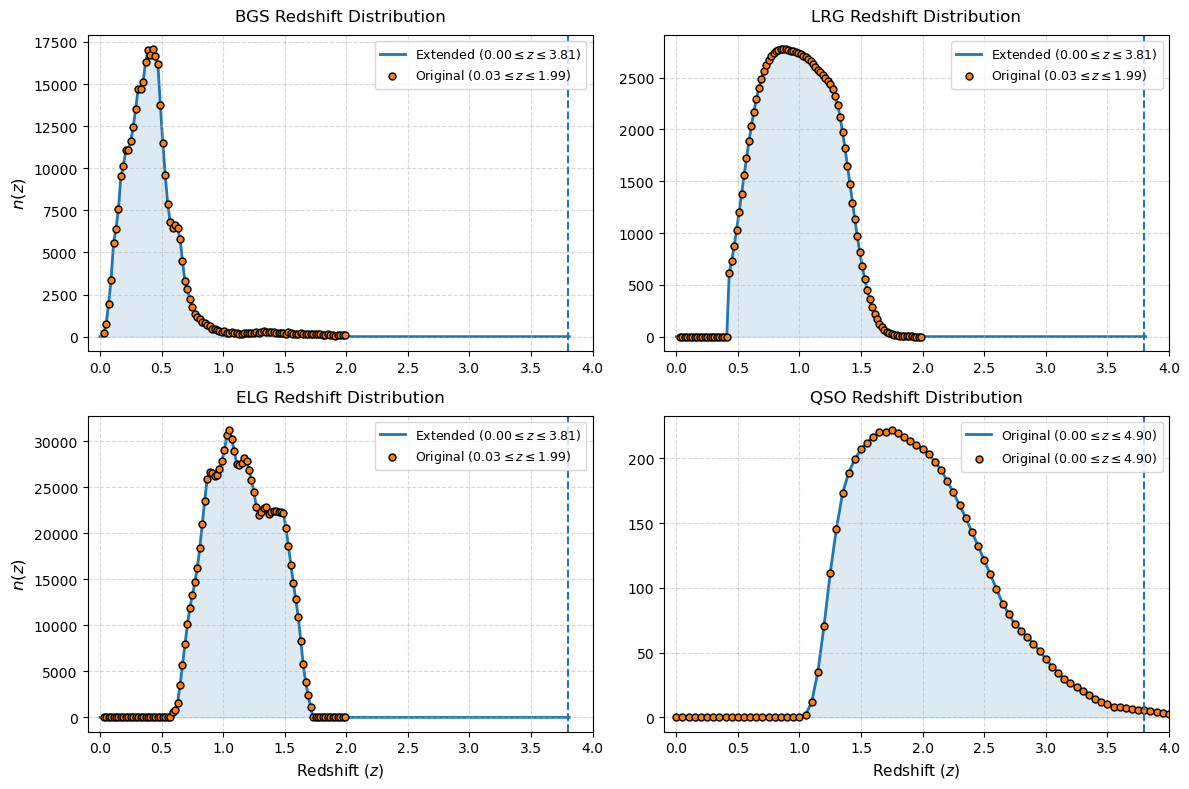

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8), dpi=100)
axs = axs.flatten()

# =====================================================================
# SUBPLOT 1: DESI BGS Distribution n(z)
# =====================================================================
axs[0].plot(
    z_nz_bgs_new,
    nz_bgs_new,
    label=rf"Extended (${z_nz_bgs_new.min():.2f} \leq z \leq {z_nz_bgs_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[0].fill_between(z_nz_bgs_new, nz_bgs_new, color="tab:blue", alpha=0.15)
axs[0].scatter(
    z_nz_bgs,
    nz_bgs,
    label=rf"Original (${z_nz_bgs.min():.2f} \leq z \leq {z_nz_bgs.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[0].set_title("BGS Redshift Distribution", fontsize=12, pad=10)
axs[0].legend(fontsize=9, loc="upper right")

# =====================================================================
# SUBPLOT 2: DESI LRG Distribution n(z)
# =====================================================================

axs[1].plot(
    z_nz_lrg_new,
    nz_lrg_new,
    label=rf"Extended (${z_nz_lrg_new.min():.2f} \leq z \leq {z_nz_lrg_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[1].fill_between(z_nz_lrg_new, nz_lrg_new, color="tab:blue", alpha=0.15)
axs[1].scatter(
    z_nz_lrg,
    nz_lrg,
    label=rf"Original (${z_nz_lrg.min():.2f} \leq z \leq {z_nz_lrg.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[1].set_title("LRG Redshift Distribution", fontsize=12, pad=10)
axs[1].legend(fontsize=9, loc="upper right")

# =====================================================================
# SUBPLOT 3: DESI ELG Distribution n(z)
# =====================================================================

axs[2].plot(
    z_nz_elg_new,
    nz_elg_new,
    label=rf"Extended (${z_nz_elg_new.min():.2f} \leq z \leq {z_nz_elg_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[2].fill_between(z_nz_elg_new, nz_elg_new, color="tab:blue", alpha=0.15)
axs[2].scatter(
    z_nz_elg,
    nz_elg,
    label=rf"Original (${z_nz_elg.min():.2f} \leq z \leq {z_nz_elg.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[2].set_title("ELG Redshift Distribution", fontsize=12, pad=10)
axs[2].legend(fontsize=9, loc="upper right")

# =====================================================================
# SUBPLOT 4: DESI QSO Distribution n(z)
# =====================================================================

axs[3].plot(
    z_nz_qso,
    nz_qso,
    label=rf"Original (${z_nz_qso.min():.2f} \leq z \leq {z_nz_qso.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[3].fill_between(z_nz_qso, nz_qso, color="tab:blue", alpha=0.15)
axs[3].scatter(
    z_nz_qso,
    nz_qso,
    label=rf"Original (${z_nz_qso.min():.2f} \leq z \leq {z_nz_qso.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[3].set_title("QSO Redshift Distribution", fontsize=12, pad=10)
axs[3].legend(fontsize=9, loc="upper right")

# =====================================================================
# GLOBAL STYLING & CLEANUP
# =====================================================================

axs[2].set_xlabel("Redshift ($z$)", fontsize=11)
axs[3].set_xlabel("Redshift ($z$)", fontsize=11)
axs[0].set_ylabel("$n(z)$", fontsize=12)
axs[2].set_ylabel("$n(z)$", fontsize=12)
for ax in axs:
    ax.set_xlim(-0.1, 4.0)
    ax.axvline(x=3.8, ls='--')
    ax.grid(True, linestyle="--", alpha=0.5)

# Tight layout handles padding automatically so text doesn't overlap
plt.tight_layout()
plt.savefig("./plots/DESI_extended_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

### extended LSST input files

In [10]:
# load the bz
z_bz, bz = np.loadtxt("inputs/bias-input/bz-input_lsst_gal_original.txt", unpack=True)

# Define the new grid parameters
dz = z_bz[1] - z_bz[0]
z_bz_new = np.arange(0, zmax + dz, dz)

# Create a smooth, non-linear interpolator
# extrapolate=True allows the cubic trend to carry past the boundaries
interp_func = PchipInterpolator(z_bz, bz, extrapolate=True)
bz_new = interp_func(z_bz_new)

# save the distribution
output_filename = "inputs/bias-input/bz-input_lsst_gal.txt"
new_data = np.column_stack((z_bz_new, bz_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

In [11]:
# load the Tz
z_Tz, Tz = np.loadtxt("inputs/thresholds/tz_lsst_gal_original.txt", unpack=True)

# Define the new grid parameters
dz = z_Tz[1] - z_Tz[0]
z_Tz_new = np.arange(0, zmax + dz, dz)

# Create a smooth, non-linear interpolator
# extrapolate=True allows the cubic trend to carry past the boundaries
interp_func = PchipInterpolator(z_Tz, Tz, extrapolate=True)
Tz_new = interp_func(z_Tz_new)

# save the perfectly preserved distribution
output_filename = "inputs/thresholds/tz_lsst_gal.txt"
new_data = np.column_stack((z_Tz_new, Tz_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

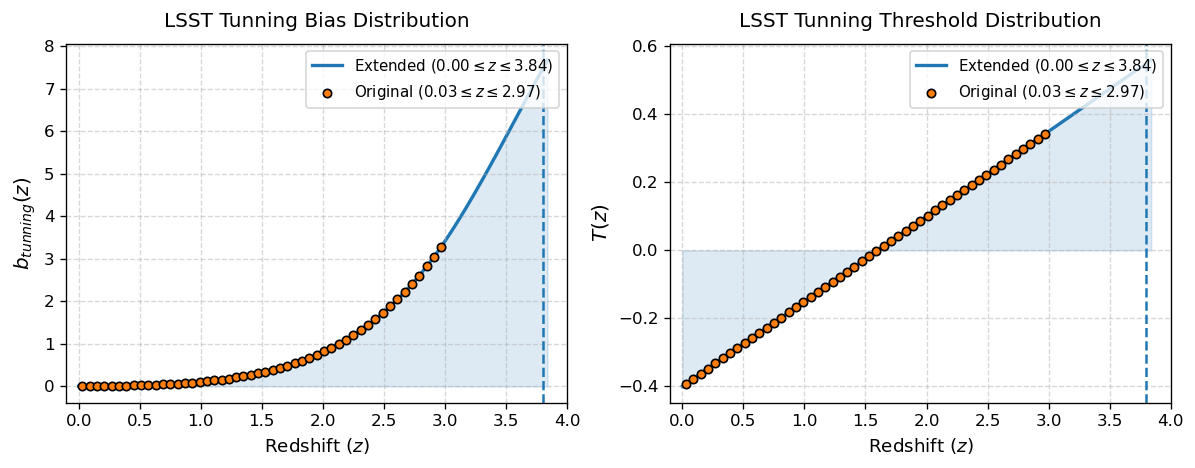

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True, dpi=120)

# =====================================================================
# SUBPLOT 2: Bias Distribution b(z)
# =====================================================================
axs[0].plot(
    z_bz_new,
    bz_new,
    label=rf"Extended (${z_bz_new.min():.2f} \leq z \leq {z_bz_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[0].fill_between(z_bz_new, bz_new, color="tab:blue", alpha=0.15)
axs[0].scatter(
    z_bz,
    bz,
    label=rf"Original (${z_bz.min():.2f} \leq z \leq {z_bz.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[0].set_title("LSST Tunning Bias Distribution", fontsize=12, pad=10)
axs[0].set_ylabel("$b_{tunning}(z)$", fontsize=12)
axs[0].legend(fontsize=9, loc="upper right")

# =====================================================================
# SUBPLOT 3: Threshold Distribution T(z)
# =====================================================================
axs[1].plot(
    z_Tz_new,
    Tz_new,
    label=rf"Extended (${z_Tz_new.min():.2f} \leq z \leq {z_Tz_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[1].fill_between(z_Tz_new, Tz_new, color="tab:blue", alpha=0.15)
axs[1].scatter(
    z_Tz,
    Tz,
    label=rf"Original (${z_Tz.min():.2f} \leq z \leq {z_Tz.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[1].set_title("LSST Tunning Threshold Distribution", fontsize=12, pad=10)
axs[1].set_ylabel("$T(z)$", fontsize=12)
axs[1].legend(fontsize=9, loc="upper right")

# =====================================================================
# GLOBAL STYLING & CLEANUP
# =====================================================================
for ax in axs:
    ax.set_xlabel("Redshift ($z$)", fontsize=11)
    ax.set_xlim(-0.1, 4.0)
    ax.axvline(x=3.8, ls='--')
    ax.grid(True, linestyle="--", alpha=0.5)

# Tight layout handles padding automatically so text doesn't overlap
plt.tight_layout()
plt.savefig("./plots/LSST_extended_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## Create real bias files

In [13]:
# choose the box for which to compare the theory and the CoLoRe Cls
box = 'test_box_7'  # options: 'third_test_box', 'fourth_test_box'
params_path = f'../{box}/cosmo_params.json'
cosmo_dict = load_cosmology(params_path)

In [14]:
# set the redshift range for the boltzmann solver
z_max = cosmo_dict["z_max"]
z_min = 0.0
nz = 250
z_pk = np.arange(z_min, z_max + 1e-9, 0.05) 

# [1/Mpc] set the maximum k for CAMB results
kmax = 100.0 

# get CAMB results
results = get_camb_results(
    cosmo_dict=cosmo_dict,
    z_pk=z_pk,
    kmax=kmax,
    nonlinear=False
)

Note: redshifts have been re-sorted (earliest first)


In [15]:
s8 = results.get_sigma8()            # comes back in the same descending-z order
D = (s8 / s8[-1])[::-1]              # D(z), normalised to D(0)=1, ascending z
f_LRG = 0.9  # Laura tunned the LRG bias down by 0.9 factor

for name, c in {"bgs": 1.34, "lrg": 1.7, "elg": 0.84}.items():
    if name == "lrg":
        np.savetxt(f"inputs/bias/bz_desi_{name}.txt", np.column_stack([z_pk, f_LRG * (c / D)]))  
    else:
        np.savetxt(f"inputs/bias/bz_desi_{name}.txt", np.column_stack([z_pk, c / D]))

## Redshift and bias distribution of all galaxies

In [16]:
# load the nz
z_nz_bgs, nz_bgs = np.loadtxt("inputs/nz/nz_desi_bgs.txt", unpack=True)
z_nz_lrg, nz_lrg = np.loadtxt("inputs/nz/nz_desi_lrg.txt", unpack=True)
z_nz_elg, nz_elg = np.loadtxt("inputs/nz/nz_desi_elg.txt", unpack=True)
z_nz_qso, nz_qso = np.loadtxt("inputs/nz/nz_desi_qso.txt", unpack=True)
z_nz_lsst, nz_lsst = np.loadtxt("inputs/nz/nz_lsst_gal.txt", unpack=True)

z_nz_array = [z_nz_bgs, z_nz_lrg, z_nz_elg, z_nz_qso, z_nz_lsst]
nz_array = [nz_bgs, nz_lrg, nz_elg, nz_qso, nz_lsst]

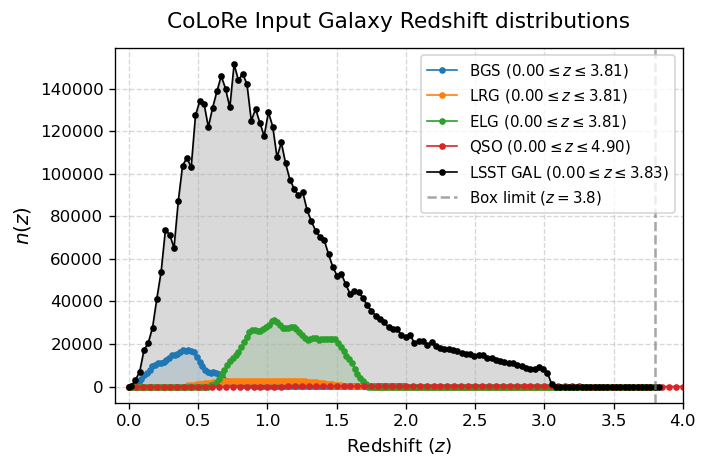

In [17]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=120)

# Map tracers to their respective data variables and colors for differentiation
tracers = [
    ("BGS", z_nz_array[0], nz_array[0], "tab:blue"),
    ("LRG", z_nz_array[1], nz_array[1], "tab:orange"),
    ("ELG", z_nz_array[2], nz_array[2], "tab:green"),
    ("QSO", z_nz_array[3], nz_array[3], "tab:red"),
    ("LSST GAL", z_nz_array[4], nz_array[4], "black"),
]

# Overlay each tracer using the line + fill_between + scatter combo style
for name, z, nz, color in tracers:
    label_str = rf"{name} (${z.min():.2f} \leq z \leq {z.max():.2f}$)"
    
    # Continuous trend line
    ax.plot(z, nz, label=label_str, color=color, lw=1, ls='-', marker='.')
    ax.fill_between(z, 0, nz, color=color, alpha=0.15)


# =====================================================================
# 3. GLOBAL STYLING & CLEANUP
# =====================================================================
ax.set_title("CoLoRe Input Galaxy Redshift distributions", fontsize=13, pad=12)
ax.set_xlabel("Redshift ($z$)", fontsize=11)
ax.set_ylabel("$n(z)$", fontsize=12)

# Apply the requested axis ranges, vertical line constraint, and grid styles
ax.set_xlim(-0.1, 4.0)
ax.axvline(x=3.8, ls='--', color='gray', alpha=0.7, label="Box limit ($z=3.8$)")
ax.grid(True, linestyle="--", alpha=0.5)

# Place legend in a clear corner with your specified text sizing
ax.legend(fontsize=9)

# Handle padding automatically so elements don't clip
plt.tight_layout()
plt.savefig("./plots/inputs_nz.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
# normalize the n(z) distributions by N
fsky = (4 * np.pi) * (180 / np.pi)**2  # multiply by the total sky area in deg**2 and redshift bin width
for i in range(len(nz_array)):
    nz_array[i] = nz_array[i] * fsky
    nz_array[i] = nz_array[i]/np.sum(nz_array[i])  # normalize to unity

In [19]:
# load the real bias files
z_bz_bgs, bz_bgs = np.loadtxt("inputs/bias/bz_desi_bgs.txt", unpack=True)
z_bz_lrg, bz_lrg = np.loadtxt("inputs/bias/bz_desi_lrg.txt", unpack=True)
z_bz_elg, bz_elg = np.loadtxt("inputs/bias/bz_desi_elg.txt", unpack=True)
z_bz_qso, bz_qso = np.loadtxt("inputs/bias/bz_desi_qso.txt", unpack=True)
z_bz_lsst, bz_lsst = np.loadtxt("inputs/bias/bz_lsst_gal.txt", unpack=True)

In [20]:
# load the input bias files
z_bz_input_bgs, bz_input_bgs = np.loadtxt("inputs/bias-input/bz-input_desi_bgs.txt", unpack=True)
z_bz_input_lrg, bz_input_lrg = np.loadtxt("inputs/bias-input/bz-input_desi_lrg.txt", unpack=True)
z_bz_input_elg, bz_input_elg = np.loadtxt("inputs/bias-input/bz-input_desi_elg.txt", unpack=True)
z_bz_input_qso, bz_input_qso = np.loadtxt("inputs/bias-input/bz-input_desi_qso.txt", unpack=True)
z_bz_input_lsst, bz_input_lsst = np.loadtxt("inputs/bias-input/bz-input_lsst_gal.txt", unpack=True)

In [21]:
# load the Tz
z_tz_bgs, tz_bgs = np.loadtxt("inputs/thresholds/tz_desi_bgs.txt", unpack=True)
z_tz_bgs_new, tz_bgs_new = np.loadtxt("inputs/thresholds/tz_desi_bgs_new.txt", unpack=True)
z_tz_lrg, tz_lrg = np.loadtxt("inputs/thresholds/tz_desi_lrg.txt", unpack=True)
z_tz_elg, tz_elg = np.loadtxt("inputs/thresholds/tz_desi_elg.txt", unpack=True)
z_tz_qso, tz_qso = np.loadtxt("inputs/thresholds/tz_desi_qso.txt", unpack=True)
z_tz_lsst, tz_lsst = np.loadtxt("inputs/thresholds/tz_lsst_gal.txt", unpack=True)

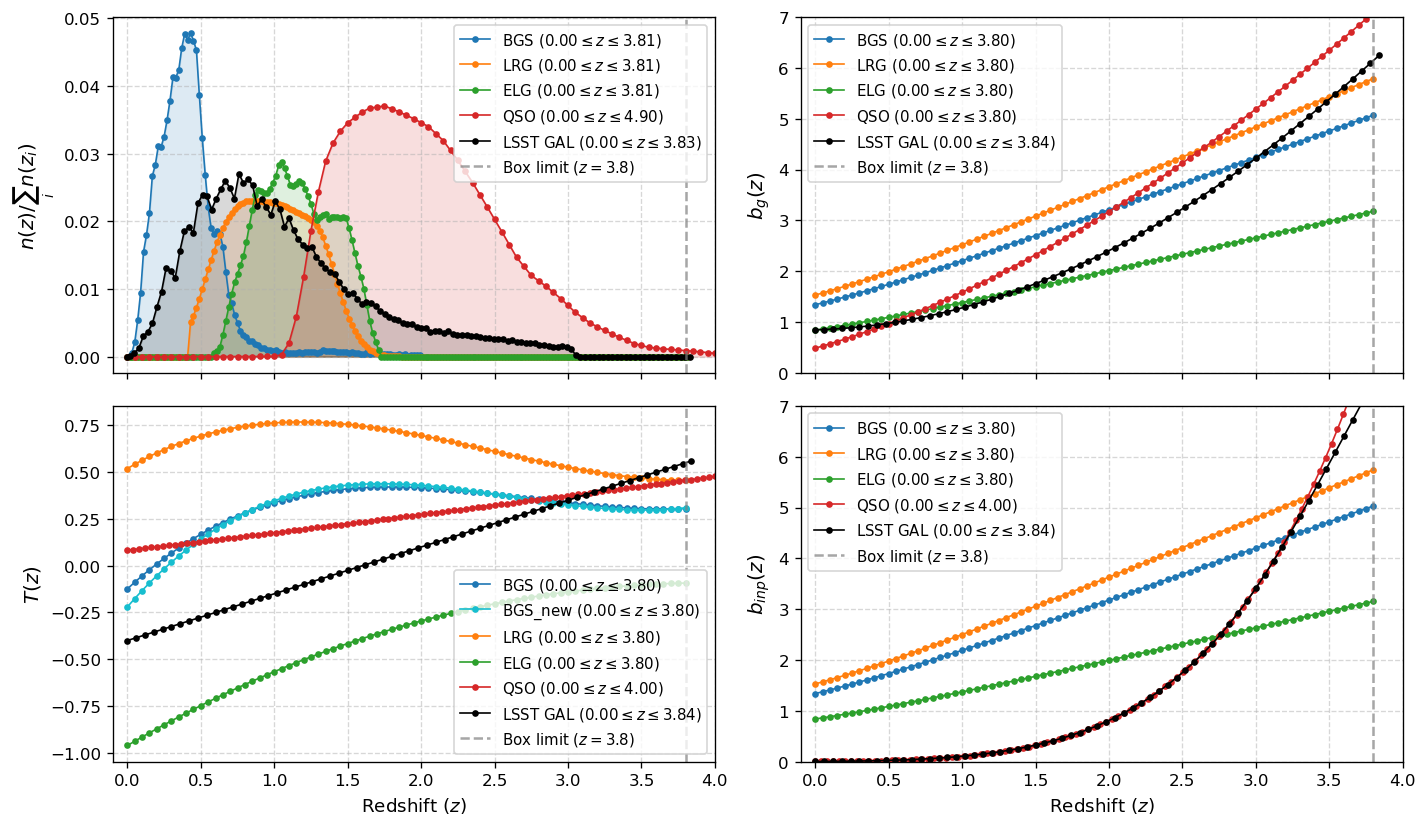

In [22]:
fig, ((ax1, ax3), (ax2, ax4)) = plt.subplots(2, 2, figsize=(12, 7), dpi=120, sharex=True)

# Map tracers to their respective data variables and colors for differentiation
tracers = [
    ("BGS", z_nz_array[0], nz_array[0], "tab:blue"),
    ("LRG", z_nz_array[1], nz_array[1], "tab:orange"),
    ("ELG", z_nz_array[2], nz_array[2], "tab:green"),
    ("QSO", z_nz_array[3], nz_array[3], "tab:red"),
    ("LSST GAL", z_nz_array[4], nz_array[4], "black"),
]

# Overlay each tracer using the line + fill_between + scatter combo style
for name, z, nz, color in tracers:
    label_str = rf"{name} (${z.min():.2f} \leq z \leq {z.max():.2f}$)"
    
    # Continuous trend line
    ax1.plot(z, nz, label=label_str, color=color, lw=1, ls='-', marker='.')
    ax1.fill_between(z, 0, nz, color=color, alpha=0.15)

ax1.set_ylabel(r"$n(z) / \sum_i n(z_i)$", fontsize=12)

# Apply the requested axis ranges, vertical line constraint, and grid styles
ax1.set_xlim(-0.1, 4.0)
ax1.axvline(x=3.8, ls='--', color='gray', alpha=0.7, label="Box limit ($z=3.8$)")
ax1.grid(True, linestyle="--", alpha=0.5)

# Place legend in a clear corner with your specified text sizing
ax1.legend(fontsize=9)

# =====================================================================

# Map tracers to their respective data variables and colors for differentiation
tracers = [
    ("BGS", z_tz_bgs, tz_bgs, "tab:blue"),
    ("BGS_new", z_tz_bgs, tz_bgs_new, "tab:cyan"),
    ("LRG", z_tz_lrg, tz_lrg, "tab:orange"),
    ("ELG", z_tz_elg, tz_elg, "tab:green"),
    ("QSO", z_tz_qso, tz_qso, "tab:red"),
    ("LSST GAL", z_tz_lsst, tz_lsst, "black"),
]

# Overlay each tracer using the line + fill_between + scatter combo style
for name, z, tz, color in tracers:
    label_str = rf"{name} (${z.min():.2f} \leq z \leq {z.max():.2f}$)"
    
    # Continuous trend line
    ax2.plot(z, tz, label=label_str, color=color, lw=1, ls='-', marker='.')

ax2.set_xlabel("Redshift ($z$)", fontsize=11)
ax2.set_ylabel("$T(z)$", fontsize=12)

# Apply the requested axis ranges, vertical line constraint, and grid styles
ax2.set_xlim(-0.1, 4.0)
ax2.axvline(x=3.8, ls='--', color='gray', alpha=0.7, label="Box limit ($z=3.8$)")
ax2.grid(True, linestyle="--", alpha=0.5)

# Place legend in a clear corner with your specified text sizing
ax2.legend(fontsize=9)

# =====================================================================

# Map tracers to their respective data variables and colors for differentiation
tracers = [
    ("BGS", z_bz_bgs, bz_bgs, "tab:blue"),
    ("LRG", z_bz_lrg, bz_lrg, "tab:orange"),
    ("ELG", z_bz_elg, bz_elg, "tab:green"),
    ("QSO", z_bz_qso, bz_qso, "tab:red"),
    ("LSST GAL", z_bz_lsst, bz_lsst, "black"),
]

# Overlay each tracer using the line + fill_between + scatter combo style
for name, z, bz, color in tracers:
    label_str = rf"{name} (${z.min():.2f} \leq z \leq {z.max():.2f}$)"
    
    # Continuous trend line
    ax3.plot(z, bz, label=label_str, color=color, lw=1, ls='-', marker='.')

ax3.set_ylabel("$b_g(z)$", fontsize=12)

# Apply the requested axis ranges, vertical line constraint, and grid styles
ax3.set_xlim(-0.1, 4.0)
ax3.set_ylim(ymin=0, ymax=7)
ax3.set_ylim(ymin=0)
ax3.axvline(x=3.8, ls='--', color='gray', alpha=0.7, label="Box limit ($z=3.8$)")
ax3.grid(True, linestyle="--", alpha=0.5)

# Place legend in a clear corner with your specified text sizing
ax3.legend(fontsize=9, loc="upper left", )

# =====================================================================

# Map tracers to their respective data variables and colors for differentiation
tracers = [
    ("BGS", z_bz_input_bgs, bz_input_bgs, "tab:blue"),
    ("LRG", z_bz_input_lrg, bz_input_lrg, "tab:orange"),
    ("ELG", z_bz_input_elg, bz_input_elg, "tab:green"),
    ("QSO", z_bz_input_qso, bz_input_qso, "tab:red"),
    ("LSST GAL", z_bz_input_lsst, bz_input_lsst, "black"),
]

# Overlay each tracer using the line + fill_between + scatter combo style
for name, z, bz, color in tracers:
    label_str = rf"{name} (${z.min():.2f} \leq z \leq {z.max():.2f}$)"
    
    # Continuous trend line
    ax4.plot(z, bz, label=label_str, color=color, lw=1, ls='-', marker='.')

ax4.set_xlabel("Redshift ($z$)", fontsize=11)
ax4.set_ylabel("$b_{inp}(z)$", fontsize=12)

# Apply the requested axis ranges, vertical line constraint, and grid styles
ax4.set_xlim(-0.1, 4.0)
ax4.set_ylim(ymin=0, ymax=7)
ax4.axvline(x=3.8, ls='--', color='gray', alpha=0.7, label="Box limit ($z=3.8$)")
ax4.grid(True, linestyle="--", alpha=0.5)

# Place legend in a clear corner with your specified text sizing
ax4.legend(fontsize=9, loc="upper left", )

# Handle padding automatically so elements don't clip
plt.tight_layout()
plt.savefig("./plots/inputs_distributions.png", dpi=300, bbox_inches="tight")
plt.show() 